# Homework 2

## 1. Combined Cycle Power Plant Data Set

### 1(a) Download the Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression

The Combined Cycle Power Plant dataset was downloaded from the UCI Machine Learning Repository. Sheet 1 of the dataset is used for this homework.

In [2]:
df = pd.read_excel("CCPP/Folds5x2_pp.xlsx", sheet_name=0)
df.head()

,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


### 1(b) Exploring the Data

#### 1(b)i Dataset Dimensions

In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Columns:", df.columns.tolist())

Number of rows: 9568
Number of columns: 5
Columns: ['AT', 'V', 'AP', 'RH', 'PE']


The dataset contains 9568 rows and 5 columns. Each row represents one hourly observation collected from the Combined Cycle Power Plant. The columns represent four predictor variables, AT (Ambient Temperature), V (Exhaust Vacuum), AP (Ambient Pressure), and RH (Relative Humidity), and one response variable, PE (net hourly electrical energy output).

#### 1(b)ii Pairwise Scatterplots

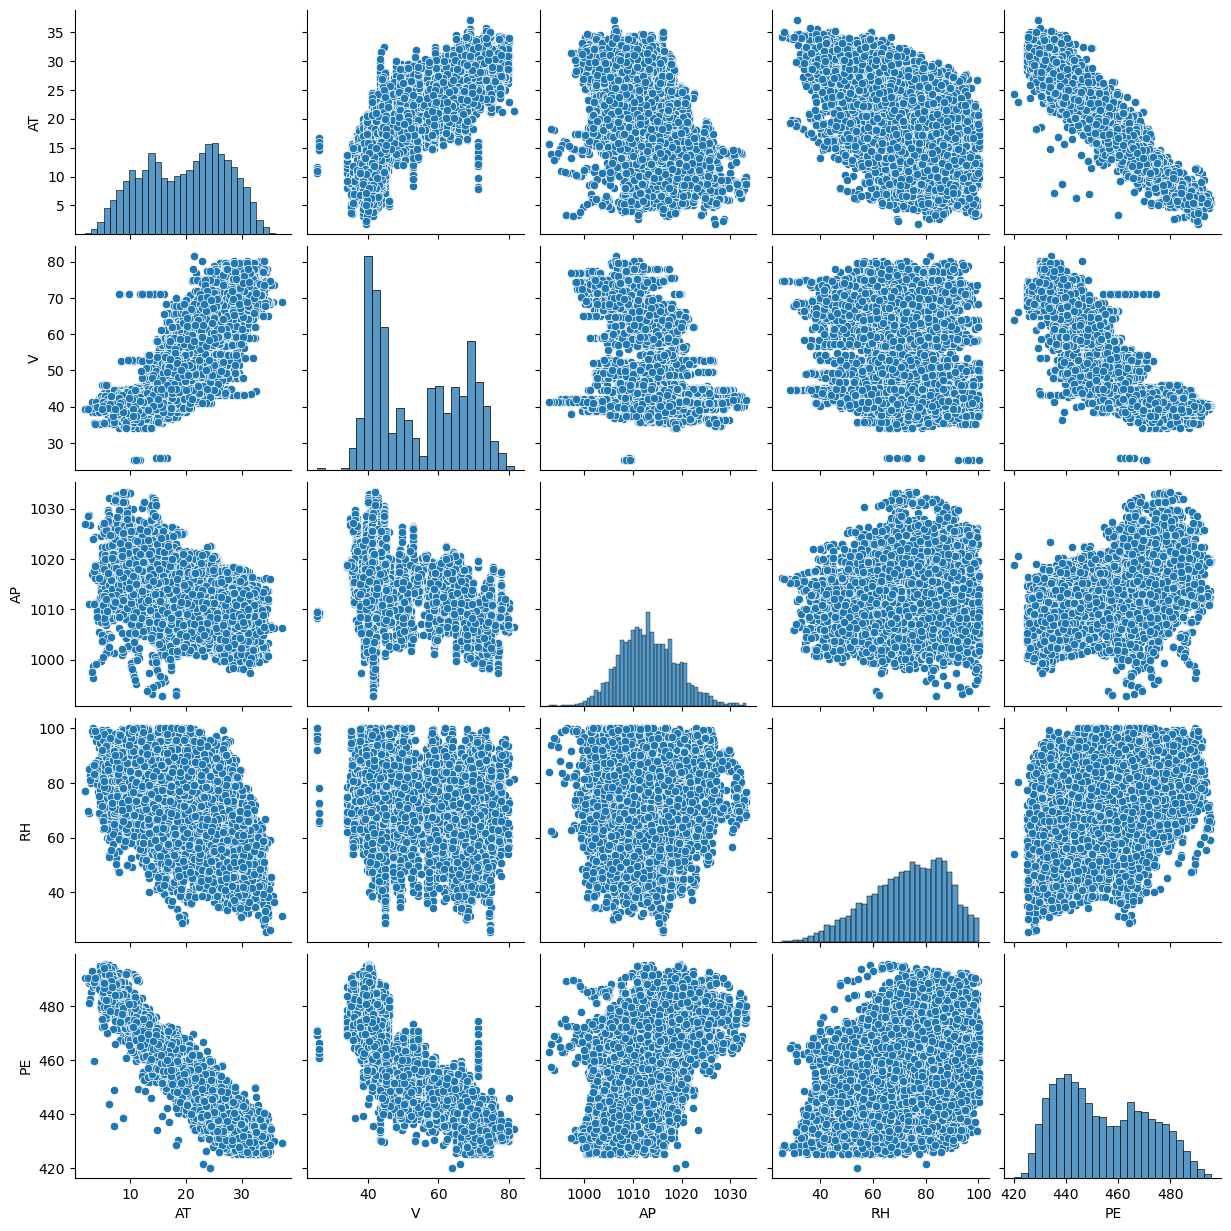

In [4]:
sns.pairplot(df)
plt.show()

From the pairwise scatterplots, PE has a strong negative relationship with AT and V. As AT or V increases, the electrical energy output tends to decrease. AP shows a positive relationship with PE, while RH also appears to have a weaker positive relationship with PE.

Among the predictors, AT and V are strongly positively associated with each other, while AT tends to be negatively associated with AP and RH. Some relationships do not appear to be perfectly linear, suggesting that nonlinear terms may be useful in later regression models.

#### 1(b)iii Summary Statistics

In [5]:
summary = pd.DataFrame({
    "Mean": df.mean(),
    "Median": df.median(),
    "Range": df.max() - df.min(),
    "First Quartile": df.quantile(0.25),
    "Third Quartile": df.quantile(0.75),
    "IQR": df.quantile(0.75) - df.quantile(0.25)
})

summary

,Mean,Median,Range,First Quartile,Third Quartile,IQR
AT,19.651231,20.345,35.30,13.5100,25.72,12.2100
V,54.305804,52.080,56.20,41.7400,66.54,24.8000
AP,1013.259078,1012.940,40.41,1009.1000,1017.26,8.1600
RH,73.308978,74.975,74.60,63.3275,84.83,21.5025
PE,454.365009,451.550,75.50,439.7500,468.43,28.6800


### 1(c) Simple Linear Regression

In [6]:
predictors = ['AT', 'V', 'AP', 'RH']

simple_models = {}

for predictor in predictors:
    X = sm.add_constant(df[predictor])
    y = df['PE']
    
    model = sm.OLS(y, X).fit()
    simple_models[predictor] = model
    
    print(f"Simple Linear Regression: PE ~ {predictor}")
    print(model.summary())
    print("\n" + "=" * 80 + "\n")

Simple Linear Regression: PE ~ AT
                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.899
Model:                            OLS   Adj. R-squared:                  0.899
Method:                 Least Squares   F-statistic:                 8.510e+04
Date:                Sun, 20 Sep 2026   Prob (F-statistic):               0.00
Time:                        17:48:42   Log-Likelihood:                -29756.
No. Observations:                9568   AIC:                         5.952e+04
Df Residuals:                    9566   BIC:                         5.953e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        497.0

All four predictors have statistically significant associations with PE (p < 0.001).

- **AT:** The coefficient is -2.1713, indicating that a one-unit increase in AT is associated with an average decrease of about 2.1713 units in PE. The model has an R-squared of 0.899, indicating a very strong linear relationship.
- **V:** The coefficient is -1.1681. A one-unit increase in V is associated with an average decrease of about 1.1681 units in PE. The R-squared is 0.757.
- **AP:** The coefficient is 1.4899. A one-unit increase in AP is associated with an average increase of about 1.4899 units in PE. The R-squared is 0.269.
- **RH:** The coefficient is 0.4557. A one-unit increase in RH is associated with an average increase of about 0.4557 units in PE. The R-squared is 0.152.

Therefore, AT has the strongest individual linear association with PE, followed by V. AP and RH are also statistically significant, although their individual linear models explain substantially less variation in PE.

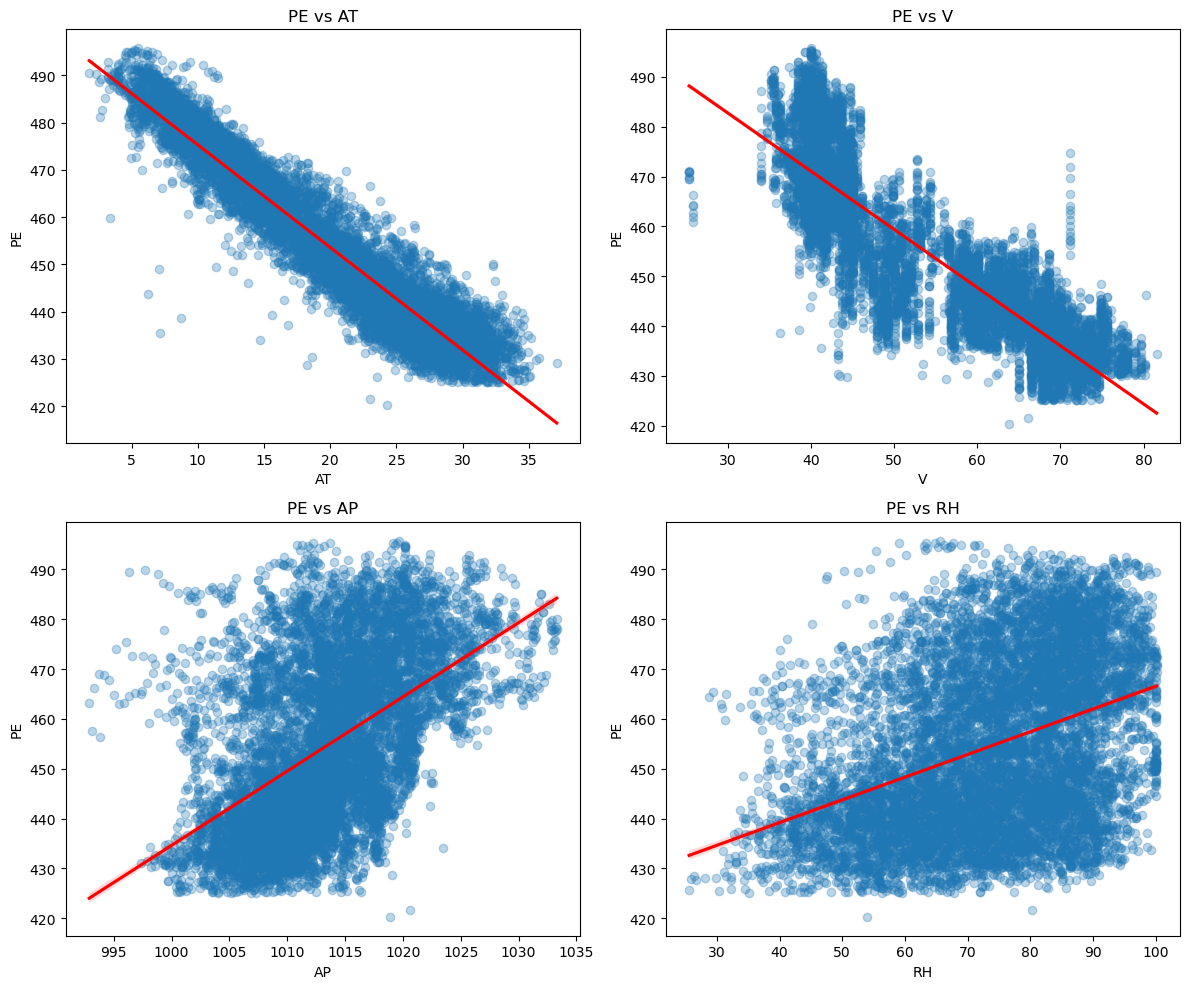

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for predictor, ax in zip(predictors, axes.flatten()):
    sns.regplot(
        x=predictor,
        y='PE',
        data=df,
        scatter_kws={'alpha': 0.3},
        line_kws={'color': 'red'},
        ax=ax
    )
    ax.set_title(f'PE vs {predictor}')

plt.tight_layout()
plt.show()

In [8]:
for predictor in predictors:
    model = simple_models[predictor]
    influence = model.get_influence()
    studentized_residuals = influence.resid_studentized_internal
    
    outliers = np.sum(np.abs(studentized_residuals) > 3)
    
    print(f"{predictor}: {outliers} observations with |studentized residual| > 3")

AT: 42 observations with |studentized residual| > 3
V: 33 observations with |studentized residual| > 3
AP: 29 observations with |studentized residual| > 3
RH: 2 observations with |studentized residual| > 3


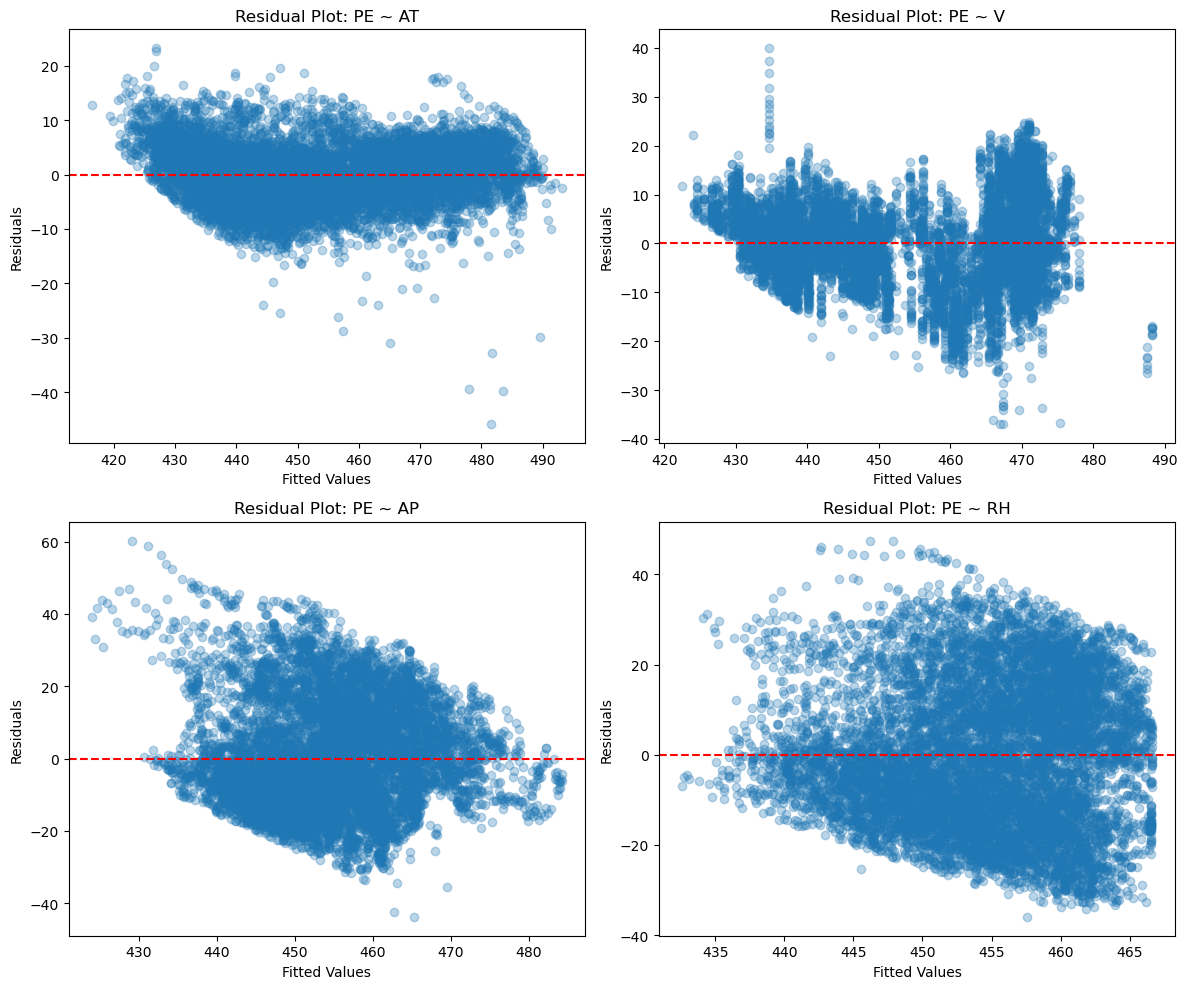

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for predictor, ax in zip(predictors, axes.flatten()):
    model = simple_models[predictor]
    
    ax.scatter(model.fittedvalues, model.resid, alpha=0.3)
    ax.axhline(y=0, color='red', linestyle='--')
    ax.set_xlabel('Fitted Values')
    ax.set_ylabel('Residuals')
    ax.set_title(f'Residual Plot: PE ~ {predictor}')

plt.tight_layout()
plt.show()

The studentized residuals indicate several potential outliers in the simple linear regression models. Using |studentized residual| > 3 as a criterion, there are 42 potential outliers for AT, 33 for V, 29 for AP, and 2 for RH.

However, these observations represent only a small portion of the dataset, and there is no evidence that they are data errors. Therefore, I would not remove them solely based on the residual criterion. They could be investigated further using leverage or influence measures if necessary.

### 1(d) Multiple Linear Regression

In [10]:
X = df[['AT', 'V', 'AP', 'RH']]
X = sm.add_constant(X)
y = df['PE']

multiple_model = sm.OLS(y, X).fit()

print(multiple_model.summary())

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.929
Model:                            OLS   Adj. R-squared:                  0.929
Method:                 Least Squares   F-statistic:                 3.114e+04
Date:                Sun, 20 Sep 2026   Prob (F-statistic):               0.00
Time:                        17:48:46   Log-Likelihood:                -28088.
No. Observations:                9568   AIC:                         5.619e+04
Df Residuals:                    9563   BIC:                         5.622e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        454.6093      9.749     46.634      0.0

The multiple linear regression model has an R-squared of 0.929, indicating that approximately 92.9% of the variation in PE is explained by the four predictors.

All four predictors are statistically significant with p-values less than 0.001. Therefore, we can reject the null hypothesis \(H_0: \beta_j = 0\) for AT, V, AP, and RH.

The estimated coefficients are -1.9775 for AT, -0.2339 for V, 0.0621 for AP, and -0.1581 for RH. Holding the other predictors constant, AT, V, and RH are negatively associated with PE, while AP is positively associated with PE.

### 1(e) Simple vs. Multiple Regression Coefficients

In [11]:
simple_coefs = [simple_models[p].params[p] for p in predictors]
multiple_coefs = [multiple_model.params[p] for p in predictors]

coef_comparison = pd.DataFrame({
    'Predictor': predictors,
    'Simple Regression Coefficient': simple_coefs,
    'Multiple Regression Coefficient': multiple_coefs
})

coef_comparison

,Predictor,Simple Regression Coefficient,Multiple Regression Coefficient
0,AT,-2.171320,-1.977513
1,V,-1.168135,-0.233916
2,AP,1.489872,0.062083
3,RH,0.455650,-0.158054


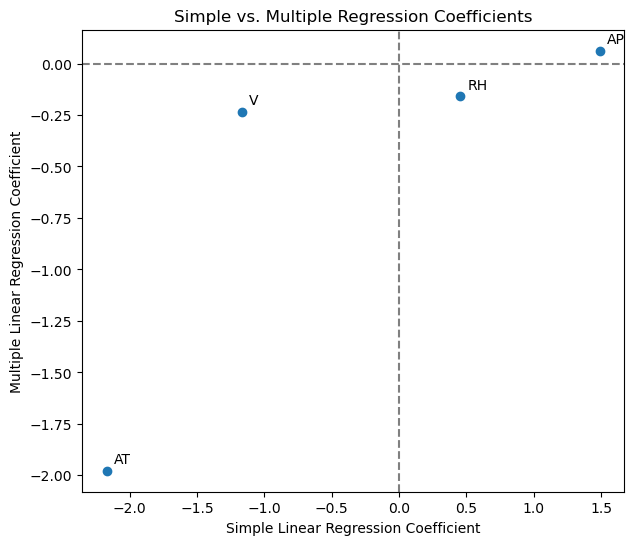

In [12]:
plt.figure(figsize=(7, 6))

plt.scatter(simple_coefs, multiple_coefs)

for i, predictor in enumerate(predictors):
    plt.annotate(
        predictor,
        (simple_coefs[i], multiple_coefs[i]),
        xytext=(5, 5),
        textcoords='offset points'
    )

plt.axhline(0, color='gray', linestyle='--')
plt.axvline(0, color='gray', linestyle='--')

plt.xlabel('Simple Linear Regression Coefficient')
plt.ylabel('Multiple Linear Regression Coefficient')
plt.title('Simple vs. Multiple Regression Coefficients')

plt.show()

The coefficients from the simple and multiple linear regression models differ considerably for several predictors.

For AT, the coefficient changes from -2.1713 in the simple regression to -1.9775 in the multiple regression, so its effect remains strongly negative.

For V, the coefficient changes from -1.1681 to -0.2339, and for AP, it changes from 1.4899 to 0.0621. Both effects become much smaller after controlling for the other predictors.

The most notable change occurs for RH: its coefficient changes from 0.4557 in the simple regression to -0.1581 in the multiple regression, reversing its sign.

These differences suggest that the predictors are correlated with one another, so the simple regression coefficients may partly reflect the effects of other variables. The multiple regression coefficients represent the association of each predictor with PE while holding the other predictors constant.

### 1(f) Nonlinear Associations

In [13]:
polynomial_models = {}

for predictor in predictors:
    formula = f"PE ~ {predictor} + I({predictor}**2) + I({predictor}**3)"
    model = smf.ols(formula=formula, data=df).fit()
    polynomial_models[predictor] = model
    
    print(f"Polynomial Regression: PE ~ {predictor} + {predictor}^2 + {predictor}^3")
    print(model.summary())
    print("\n" + "=" * 80 + "\n")

Polynomial Regression: PE ~ AT + AT^2 + AT^3
                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.912
Model:                            OLS   Adj. R-squared:                  0.912
Method:                 Least Squares   F-statistic:                 3.299e+04
Date:                Sun, 20 Sep 2026   Prob (F-statistic):               0.00
Time:                        17:48:46   Log-Likelihood:                -29101.
No. Observations:                9568   AIC:                         5.821e+04
Df Residuals:                    9564   BIC:                         5.824e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Interce

There is evidence of nonlinear association between the predictors and PE.

- **AT:** Both the quadratic term \(AT^2\) and the cubic term \(AT^3\) are statistically significant (p < 0.001), providing strong evidence of a nonlinear relationship between AT and PE.
- **V:** The quadratic term \(V^2\) is not statistically significant (p = 0.768), but the cubic term \(V^3\) is statistically significant (p = 0.014). Therefore, there is some evidence of a nonlinear relationship between V and PE.
- **AP:** Both \(AP^2\) and \(AP^3\) are statistically significant (p < 0.001), indicating evidence of nonlinear association between AP and PE.
- **RH:** Both \(RH^2\) and \(RH^3\) are statistically significant (p < 0.001), indicating evidence of nonlinear association between RH and PE.

Overall, all four predictors show some evidence of nonlinear association with PE, although the evidence for V is weaker because its quadratic term is not significant.

### 1(g) Interaction Effects

In [14]:
interaction_model = smf.ols(
    formula='PE ~ AT * V + AT * AP + AT * RH + V * AP + V * RH + AP * RH',
    data=df
).fit()

print(interaction_model.summary())

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.936
Model:                            OLS   Adj. R-squared:                  0.936
Method:                 Least Squares   F-statistic:                 1.405e+04
Date:                Sun, 20 Sep 2026   Prob (F-statistic):               0.00
Time:                        17:48:46   Log-Likelihood:                -27548.
No. Observations:                9568   AIC:                         5.512e+04
Df Residuals:                    9557   BIC:                         5.520e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    685.7825     78.640      8.721      0.0

There is evidence that several pairwise interactions are associated with PE.

The statistically significant interaction terms are:

- **AT:V** (p < 0.001)
- **AT:RH** (p < 0.001)
- **V:AP** (p < 0.001)
- **AP:RH** (p = 0.034)

The interaction terms **AT:AP** (p = 0.452) and **V:RH** (p = 0.086) are not statistically significant at the 0.05 significance level.

Therefore, the effect of some predictors on PE depends on the values of other predictors.

### 1(h) Model Improvement and MSE Comparison

In [15]:
X = df[['AT', 'V', 'AP', 'RH']]
y = df['PE']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)

print("Training set size:", X_train.shape[0])
print("Test set size:", X_test.shape[0])

Training set size: 6697
Test set size: 2871


In [16]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_train_pred = linear_model.predict(X_train)
y_test_pred = linear_model.predict(X_test)

linear_train_mse = mean_squared_error(y_train, y_train_pred)
linear_test_mse = mean_squared_error(y_test, y_test_pred)

print("Linear Regression Train MSE:", linear_train_mse)
print("Linear Regression Test MSE:", linear_test_mse)

Linear Regression Train MSE: 20.580839725738695
Linear Regression Test MSE: 21.2398569382255


In [17]:
train_df = X_train.copy()
train_df['PE'] = y_train

full_formula = (
    'PE ~ AT + V + AP + RH '
    '+ I(AT**2) + I(V**2) + I(AP**2) + I(RH**2) '
    '+ AT:V + AT:AP + AT:RH + V:AP + V:RH + AP:RH'
)

full_model = smf.ols(formula=full_formula, data=train_df).fit()

print(full_model.summary())

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.938
Model:                            OLS   Adj. R-squared:                  0.938
Method:                 Least Squares   F-statistic:                     7272.
Date:                Sun, 20 Sep 2026   Prob (F-statistic):               0.00
Time:                        17:48:46   Log-Likelihood:                -19160.
No. Observations:                6697   AIC:                         3.835e+04
Df Residuals:                    6682   BIC:                         3.845e+04
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -7664.9809   1429.568     -5.362      0.0

In [18]:
full_model.pvalues

Intercept     8.518151e-08
AT            4.460633e-02
V             2.671816e-01
AP            9.534685e-09
RH            1.429286e-04
I(AT ** 2)    5.017196e-07
I(V ** 2)     6.998020e-01
I(AP ** 2)    8.522142e-09
I(RH ** 2)    1.395087e-09
AT:V          3.195237e-03
AT:AP         1.966307e-01
AT:RH         3.056335e-03
V:AP          3.811800e-01
V:RH          8.673824e-01
AP:RH         2.937919e-04
dtype: float64

Based on the p-values of the full model, the insignificant terms I(V**2), AT:AP, V:AP, and V:RH were removed. Although the main effect V is not statistically significant in the full model, it is retained because V is involved in the significant interaction AT:V, following the hierarchical principle.

In [19]:
reduced_formula = (
    'PE ~ AT + V + AP + RH '
    '+ I(AT**2) + I(AP**2) + I(RH**2) '
    '+ AT:V + AT:RH + AP:RH'
)

reduced_model = smf.ols(
    formula=reduced_formula,
    data=train_df
).fit()

print(reduced_model.summary())

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.938
Model:                            OLS   Adj. R-squared:                  0.938
Method:                 Least Squares   F-statistic:                 1.017e+04
Date:                Sun, 20 Sep 2026   Prob (F-statistic):               0.00
Time:                        17:48:46   Log-Likelihood:                -19166.
No. Observations:                6697   AIC:                         3.835e+04
Df Residuals:                    6686   BIC:                         3.843e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -1.046e+04   1091.512     -9.581      0.0

In [20]:
reduced_model.pvalues

Intercept      1.325324e-21
AT            2.671314e-124
V              4.960489e-45
AP             1.534727e-22
RH             6.572307e-14
I(AT ** 2)     8.530847e-14
I(AP ** 2)     1.653455e-21
I(RH ** 2)     2.519751e-14
AT:V           3.753670e-08
AT:RH          2.412307e-15
AP:RH          4.829041e-13
dtype: float64

In [21]:
train_pred_reduced = reduced_model.predict(train_df)

test_df = X_test.copy()
test_df['PE'] = y_test
test_pred_reduced = reduced_model.predict(test_df)

reduced_train_mse = mean_squared_error(y_train, train_pred_reduced)
reduced_test_mse = mean_squared_error(y_test, test_pred_reduced)

print("Reduced Model Train MSE:", reduced_train_mse)
print("Reduced Model Test MSE:", reduced_test_mse)

Reduced Model Train MSE: 17.91781267118549
Reduced Model Test MSE: 18.694346190803156


In [22]:
mse_comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Reduced Interaction/Quadratic Model'],
    'Train MSE': [linear_train_mse, reduced_train_mse],
    'Test MSE': [linear_test_mse, reduced_test_mse]
})

mse_comparison

,Model,Train MSE,Test MSE
0,Linear Regression,20.580840,21.239857
1,Reduced Interaction/Quadratic Model,17.917813,18.694346


The ordinary multiple linear regression model has a training MSE of 20.5808 and a test MSE of 21.2399.

After including quadratic terms and pairwise interaction terms and removing insignificant terms while respecting the hierarchical principle, the reduced model has a training MSE of 17.9178 and a test MSE of 18.6943.

Both the training and test MSEs are lower for the reduced interaction/quadratic model. Therefore, incorporating nonlinear effects and selected interaction terms improves the predictive performance of the linear regression model.

### 1(i) KNN Regression

In [29]:
k_values = range(1, 101)

raw_train_mse = []
raw_test_mse = []

for k in k_values:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X_train, y_train)
    
    train_pred = knn.predict(X_train)
    test_pred = knn.predict(X_test)
    
    raw_train_mse.append(mean_squared_error(y_train, train_pred))
    raw_test_mse.append(mean_squared_error(y_test, test_pred))

best_k_raw = list(k_values)[np.argmin(raw_test_mse)]

print("Best k for raw features:", best_k_raw)
print("Best raw feature test MSE:", min(raw_test_mse))

Best k for raw features: 5
Best raw feature test MSE: 15.726819842563568


In [31]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

norm_train_mse = []
norm_test_mse = []

for k in k_values:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    
    train_pred = knn.predict(X_train_scaled)
    test_pred = knn.predict(X_test_scaled)
    
    norm_train_mse.append(mean_squared_error(y_train, train_pred))
    norm_test_mse.append(mean_squared_error(y_test, test_pred))

best_k_norm = list(k_values)[np.argmin(norm_test_mse)]

print("Best k for normalized features:", best_k_norm)
print("Best normalized feature test MSE:", min(norm_test_mse))

Best k for normalized features: 4
Best normalized feature test MSE: 14.305669422675024


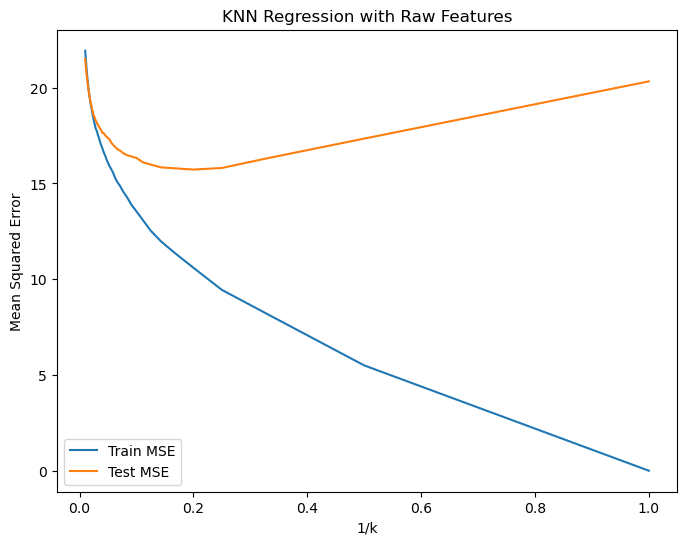

In [32]:
inverse_k = [1 / k for k in k_values]

plt.figure(figsize=(8, 6))

plt.plot(inverse_k, raw_train_mse, label='Train MSE')
plt.plot(inverse_k, raw_test_mse, label='Test MSE')

plt.xlabel('1/k')
plt.ylabel('Mean Squared Error')
plt.title('KNN Regression with Raw Features')
plt.legend()

plt.show()

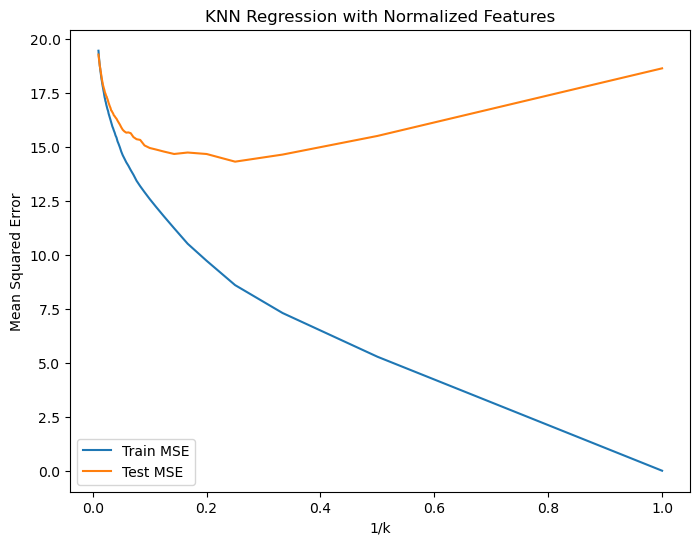

In [33]:
plt.figure(figsize=(8, 6))

plt.plot(inverse_k, norm_train_mse, label='Train MSE')
plt.plot(inverse_k, norm_test_mse, label='Test MSE')

plt.xlabel('1/k')
plt.ylabel('Mean Squared Error')
plt.title('KNN Regression with Normalized Features')
plt.legend()

plt.show()

For the raw features, the best value of \(k\) is 5, with a test MSE of 15.7268.

For the normalized features, the best value of \(k\) is 4, with a test MSE of 14.3057.

The normalized features produce a lower test MSE than the raw features. This is expected because KNN is based on distances between observations, and predictors measured on different scales can disproportionately affect the distance calculation. Standardizing the predictors places them on comparable scales and improves the performance of the KNN regression model.

### 1(j) KNN vs. Linear Regression

In [34]:
final_comparison = pd.DataFrame({
    'Model': [
        'Reduced Interaction/Quadratic Regression',
        'KNN Regression with Normalized Features'
    ],
    'Test MSE': [
        reduced_test_mse,
        min(norm_test_mse)
    ]
})

final_comparison

,Model,Test MSE
0,Reduced Interaction/Quadratic Regression,18.694346
1,KNN Regression with Normalized Features,14.305669


The reduced interaction/quadratic regression model has a test MSE of 18.6943, while the best KNN regression model using normalized features has a test MSE of 14.3057 with \(k=4\).

Therefore, KNN regression achieves a lower test error on this dataset. This suggests that the relationship between the predictors and PE may contain nonlinear or local patterns that are captured more effectively by KNN than by the fitted regression model.

Normalization also improves KNN performance, reducing the best test MSE from 15.7268 with raw features to 14.3057 with normalized features.

## 2. ISLR 2.4.1

(a) We would generally expect a flexible statistical learning method to perform better. Since the sample size \(n\) is extremely large and the number of predictors \(p\) is small, there is enough data to estimate a more flexible model reliably. The risk of overfitting is relatively low.

(b) We would generally expect a flexible method to perform worse. When \(p\) is extremely large relative to the small number of observations \(n\), a flexible model is more likely to overfit the limited training data and have high variance.

(c) We would generally expect a flexible method to perform better. If the true relationship between the predictors and the response is highly non-linear, a flexible method is better able to capture the complex relationship, while an inflexible method may suffer from high bias.

(d) We would generally expect a flexible method to perform worse. When the variance of the error terms is extremely high, much of the variation in the response is due to noise. A flexible method may fit this noise and therefore overfit, resulting in poor test performance.

## 3. ISLR 2.4.7

(a) The Euclidean distance from each observation to the test point \((0,0,0)\) is:

- Observation 1: $\sqrt{0^2 + 3^2 + 0^2} = 3$
- Observation 2: $\sqrt{2^2 + 0^2 + 0^2} = 2$
- Observation 3: $\sqrt{0^2 + 1^2 + 3^2} = \sqrt{10}$
- Observation 4: $\sqrt{0^2 + 1^2 + 2^2} = \sqrt{5}$
- Observation 5: $\sqrt{(-1)^2 + 0^2 + 1^2} = \sqrt{2}$
- Observation 6: $\sqrt{1^2 + 1^2 + 1^2} = \sqrt{3}$

(b) With $K=1$, the nearest observation is Observation 5, whose response is Green. Therefore, the prediction is **Green**.

(c) With $K=3$, the three nearest observations are:

- Observation 5: Green
- Observation 6: Red
- Observation 2: Red

Since two of the three nearest neighbors are Red, the prediction is **Red**.

(d) If the Bayes decision boundary is highly non-linear, we would generally expect the best value of $K$ to be small. A smaller $K$ produces a more flexible decision boundary that can better capture a highly non-linear relationship. A large $K$ would produce a smoother and less flexible boundary.